In [3]:
from preprocessing import clean_data, genre_map
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
df = pd.read_csv("hf://datasets/maharshipandya/spotify-tracks-dataset/dataset.csv")

In [5]:
main_df = clean_data(df)

In [6]:
main_df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,genre_group
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,indie_folk
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,indie_folk
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,indie_folk
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,indie_folk
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,indie_folk


# Feature Analysis

In [7]:
features = ['danceability','energy','loudness','speechiness','acousticness','instrumentalness','liveness','valence','tempo','duration_ms']

In [8]:
means = main_df.groupby('genre_group')[features].mean()
means

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
genre_group,,,,,,,,,,
chill_jazz_classical,0.460717,0.351055,-14.818127,0.070246,0.666447,0.405695,0.193062,0.327215,110.025047,207364.628035
country,0.553581,0.495777,-9.654077,0.039255,0.534774,0.066965,0.199372,0.594754,122.505385,195604.065299
electronic_dance,0.635025,0.743288,-7.066733,0.085059,0.126818,0.292650,0.193984,0.441543,127.361490,254787.415424
hiphop_rnb,0.627032,0.633973,-6.753481,0.102411,0.300468,0.026903,0.220822,0.506812,120.437885,233334.204363
indie_folk,0.555598,0.483863,-9.173462,0.054515,0.521934,0.036795,0.162817,0.438080,119.771602,232183.775779
kids,0.632768,0.527195,-10.763945,0.270756,0.552025,0.117321,0.296240,0.548311,114.482729,169494.310537
latin,0.612751,0.660448,-7.082074,0.077370,0.437036,0.021933,0.305996,0.635978,123.146746,224990.683958
pop,0.553293,0.646469,-7.606754,0.067489,0.335621,0.072503,0.200065,0.479087,126.074654,232742.271293
reggae,0.676708,0.731144,-6.084866,0.136783,0.187138,0.010495,0.209455,0.669235,121.028566,209593.475528


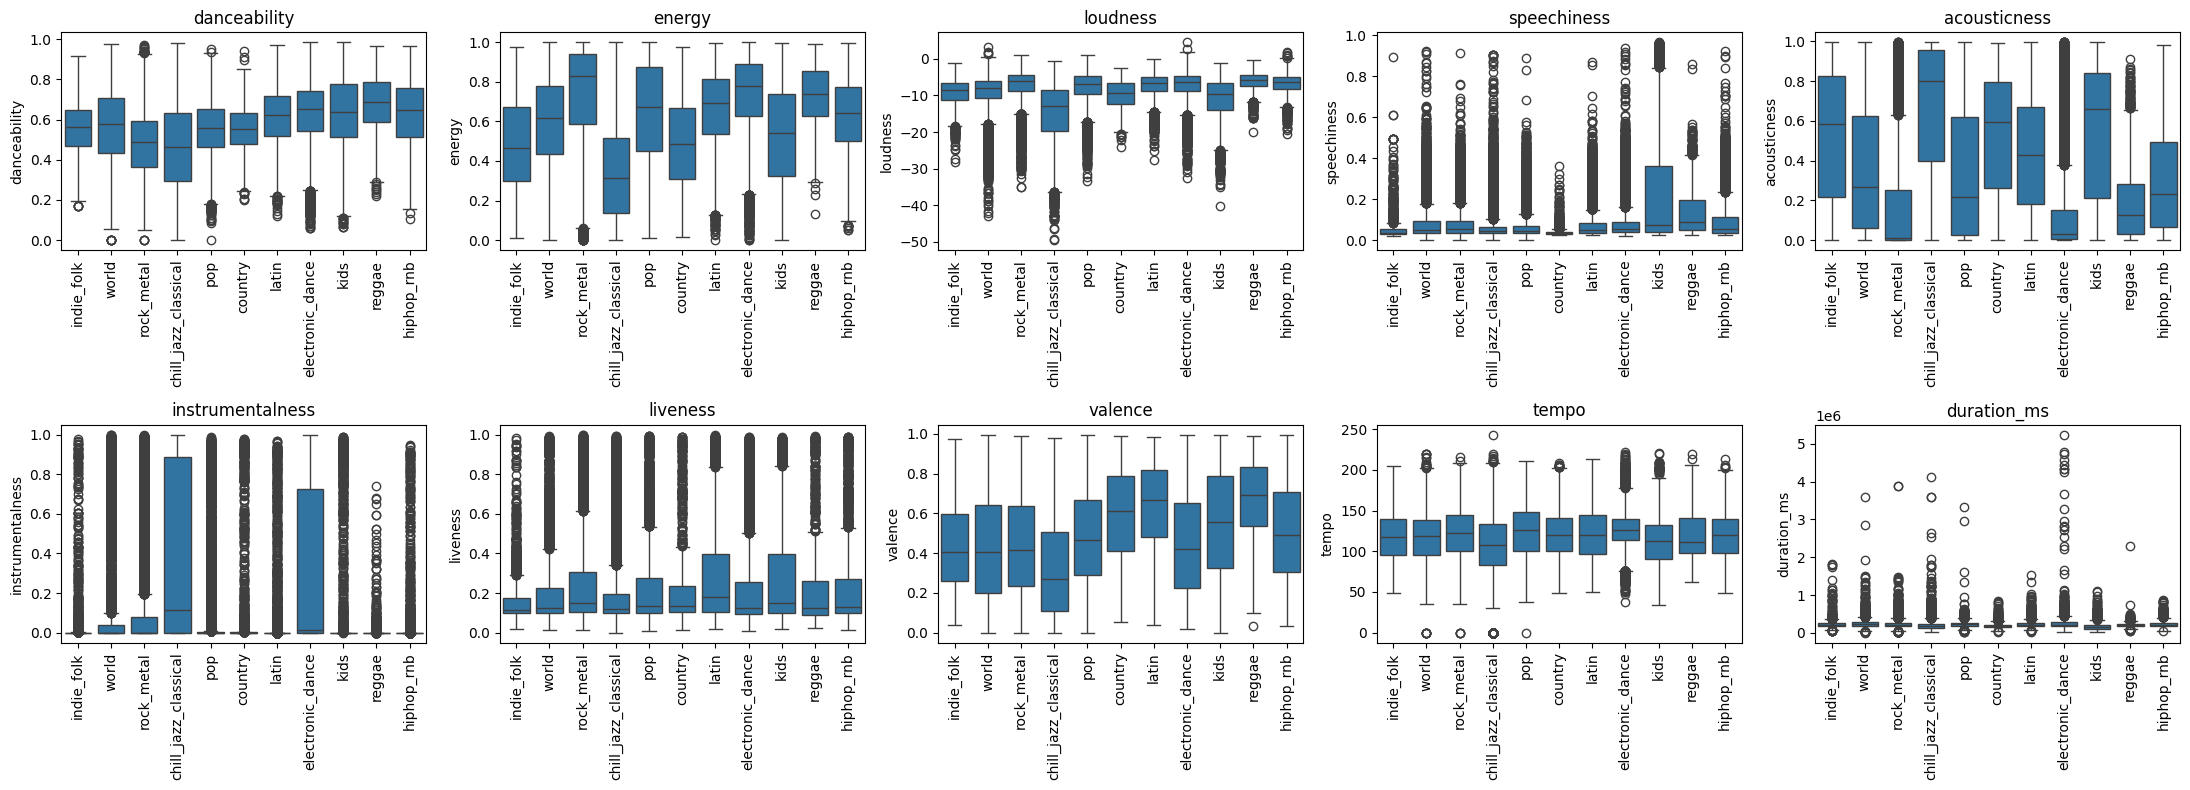

In [9]:
# Standardize each feature across the genre groups (column-wise z-score)
scaled = (means - means.mean()) / means.std()

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, feat in zip(axes.flat, features):
    sns.boxplot(data=main_df, x='genre_group', y=feat, ax=ax)
    ax.set_title(feat)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

The above figs show the distribution of each feature.

We can see that acousticness, energy, valence have clear distributions for the features, meaning those features may have a stronger impact on the predictions. duration_ms sees to vary alot and carry a lot of outliers, and may need to consider dropping as a feature due to outliers. And similiarly with liveness. Though instrumentalness has many outliers, it may be a strong predictor for chill_jazz_classical and electrocnic_dance.

# Test Train Split